# Insurance Fraud Detection — Bước 1: EDA & Imbalance Analysis
**Dataset:** Auto Insurance Fraud Claims (Kaggle)  
**Output:** `fraud_cleaned.csv` · `eda_summary.json`

---
### Cấu trúc notebook
1. Cài đặt & cấu hình
2. Load & kiểm tra dữ liệu thô
3. Phân tích biến mục tiêu — fraud distribution
4. Phân tích imbalance — tại sao Accuracy là metric sai
5. EDA biến categorical
6. EDA biến numerical
7. Correlation & multicollinearity
8. Phân tích theo thời gian (claim patterns)
9. Xử lý missing values & encoding sơ bộ
10. Lưu dữ liệu sạch & EDA summary


## Fraud Detection vs Credit Scoring — Tại sao khác nhau?

| Tiêu chí | Credit Scoring (Dự án 1) | Fraud Detection (Dự án 2) |
|---|---|---|
| Tỷ lệ sự kiện | 6.7% default | ~24% fraud |
| Metric chính | AUC / Gini / KS | PR-AUC / F1 / Recall |
| Model | Logistic Regression | XGBoost |
| Interpretability | Bắt buộc (Basel II) | SHAP (tự chọn) |
| Cost asymmetry | Balanced | Bắt fraud > Tránh false positive |
| Feature engineering | WOE binning | Free-form (thời gian, hành vi) |

### Tại sao Accuracy vô nghĩa với fraud?

Nếu model luôn predict "không fraud" → Accuracy = 76% (vì 76% claims là legit).  
Nhưng model đó **bắt được 0 fraud case** — hoàn toàn vô dụng.

**Metric đúng:**
- **Recall** = TP / (TP + FN) → Bắt được bao nhiêu % fraud thực sự?
- **Precision** = TP / (TP + FP) → Trong số bị flag, bao nhiêu % thực sự là fraud?
- **PR-AUC** = Area under Precision-Recall curve → Tổng hợp cả hai
- **F1** = Harmonic mean của Precision và Recall

## 1.Seting and Setup source

In [8]:
import warnings, json
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr

pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.max_rows", 60)

plt.rcParams.update({
    "figure.dpi": 115,
    "figure.figsize": (12, 5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlepad": 10,
    "font.family": "sans-serif",
})

PALETTE = {
    "fraud":   "#E53935",
    "legit":   "#2196F3",
    "neutral": "#78909C",
    "warn":    "#FF8F00",
    "good":    "#43A047",
}

print("✓ Setup hoàn tất")

✓ Setup hoàn tất


## 2. Load and Check raw data

In [11]:
df_raw = pd.read_csv("insurance_claims.csv")

# Đổi tên target cho nhất quán
df_raw = df_raw.rename(columns={"fraud_reported": "target"})
df_raw["target"] = (df_raw["target"] == "Y").astype(int)

print(f"Shape  : {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
print(f"Memory : {df_raw.memory_usage(deep=True).sum() / 1024:.1f} KB")
print()

# Phân loại cột
NUM_COLS  = df_raw.select_dtypes(include=["int64","float64"]).columns.tolist()
CAT_COLS  = df_raw.select_dtypes(include=["object"]).columns.tolist()
NUM_COLS  = [c for c in NUM_COLS if c != "target"]

print(f"Numerical   ({len(NUM_COLS)}): {NUM_COLS}")
print(f"Categorical ({len(CAT_COLS)}): {CAT_COLS}")
print()
df_raw.head(3)

Shape  : 1,000 rows x 40 columns
Memory : 1270.6 KB

Numerical   (19): ['months_as_customer', 'age', 'policy_number', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_year', '_c39']
Categorical (20): ['policy_bind_date', 'policy_state', 'policy_csl', 'insured_sex', 'insured_education_level', 'insured_occupation', 'insured_hobbies', 'insured_relationship', 'incident_date', 'incident_type', 'collision_type', 'incident_severity', 'authorities_contacted', 'incident_state', 'incident_city', 'incident_location', 'property_damage', 'police_report_available', 'auto_make', 'auto_model']



,months_as_customer,age,policy_number,policy_bind_date,policy_state,policy_csl,policy_deductable,policy_annual_premium,umbrella_limit,insured_zip,insured_sex,insured_education_level,insured_occupation,insured_hobbies,insured_relationship,capital-gains,capital-loss,incident_date,incident_type,collision_type,incident_severity,authorities_contacted,incident_state,incident_city,incident_location,incident_hour_of_the_day,number_of_vehicles_involved,property_damage,bodily_injuries,witnesses,police_report_available,total_claim_amount,injury_claim,property_claim,vehicle_claim,auto_make,auto_model,auto_year,target,_c39
0,328,48,521585,2014-10-17,OH,250/500,1000,"1,406.9100",0,466132,MALE,MD,craft-repair,sleeping,husband,53300,0,2015-01-25,Single Vehicle Collision,Side Collision,Major Damage,Police,SC,Columbus,9935 4th Drive,5,1,YES,1,2,YES,71610,6510,13020,52080,Saab,92x,2004,1,NaN
1,228,42,342868,2006-06-27,IN,250/500,2000,"1,197.2200",5000000,468176,MALE,MD,machine-op-inspct,reading,other-relative,0,0,2015-01-21,Vehicle Theft,?,Minor Damage,Police,VA,Riverwood,6608 MLK Hwy,8,1,?,0,0,?,5070,780,780,3510,Mercedes,E400,2007,1,NaN
2,134,29,687698,2000-09-06,OH,100/300,2000,"1,413.1400",5000000,430632,FEMALE,PhD,sales,board-games,own-child,35100,0,2015-02-22,Multi-vehicle Collision,Rear Collision,Minor Damage,Police,NY,Columbus,7121 Francis Lane,7,3,NO,2,3,NO,34650,7700,3850,23100,Dodge,RAM,2007,0,NaN


In [13]:
# Tổng quan dtypes + sample values
print("── Thống kê mô tả numerical ──")
print(df_raw[NUM_COLS].describe(percentiles=[.01,.25,.5,.75,.99]).T.round(2).to_string())


── Thống kê mô tả numerical ──
                                 count           mean            std             min           1%          25%          50%          75%            99%             max
months_as_customer          1,000.0000       203.9500       115.1100          0.0000       4.0000     115.7500     199.5000     276.2500       467.0100        479.0000
age                         1,000.0000        38.9500         9.1400         19.0000      23.0000      32.0000      38.0000      44.0000        61.0000         64.0000
policy_number               1,000.0000   546,238.6500   257,063.0100    100,804.0000 110,121.6200 335,980.2500 533,135.0000 759,099.7500   991,002.8200    999,435.0000
policy_deductable           1,000.0000     1,136.0000       611.8600        500.0000     500.0000     500.0000   1,000.0000   2,000.0000     2,000.0000      2,000.0000
policy_annual_premium       1,000.0000     1,256.4100       244.1700        433.3300     694.2200   1,089.6100   1,257.2000   1,4

## 3. Target variable analysis -  Fraud Disstribution

Target distribution:
  Legit (0) : 753  (75.3%)
  Fraud (1) : 247  (24.7%)
  Imbalance ratio: 3.0:1


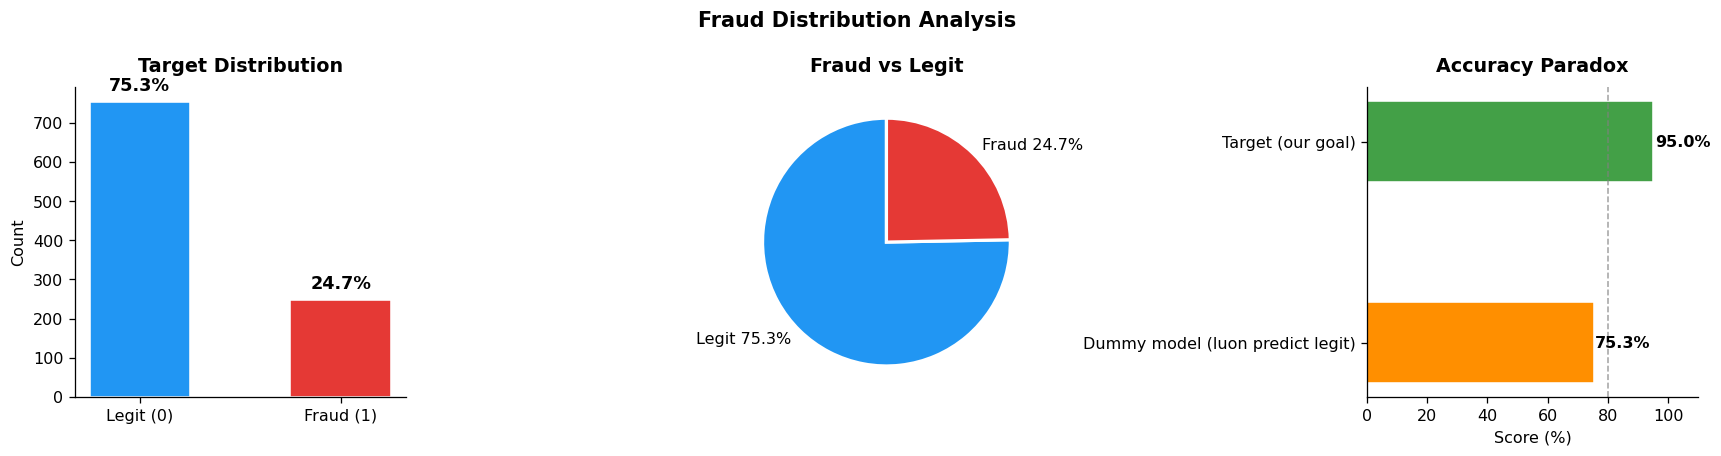

In [22]:
fraud_counts = df_raw["target"].value_counts()
fraud_pct    = df_raw["target"].value_counts(normalize=True) * 100

print("Target distribution:")
print(f"  Legit (0) : {fraud_counts[0]:,}  ({fraud_pct[0]:.1f}%)")
print(f"  Fraud (1) : {fraud_counts[1]:,}  ({fraud_pct[1]:.1f}%)")
print(f"  Imbalance ratio: {fraud_counts[0]/fraud_counts[1]:.1f}:1")

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Bar chart
bars = axes[0].bar(
    ["Legit (0)", "Fraud (1)"],
    fraud_counts.values,
    color=[PALETTE["legit"], PALETTE["fraud"]],
    width=0.5, edgecolor="white",
)
for bar, pct in zip(bars, fraud_pct.values):
    axes[0].text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 30,
        f"{pct:.1f}%", ha="center", fontsize=11, fontweight="bold",
    )
axes[0].set_title("Target Distribution")
axes[0].set_ylabel("Count")
axes[0].yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f"{x:,.0f}"))

# Pie
leg_label   = f"Legit {fraud_pct[0]:.1f}%"
fraud_label = f"Fraud {fraud_pct[1]:.1f}%"

axes[1].pie(
    fraud_counts.values,
    labels=[leg_label, fraud_label],
    colors=[PALETTE["legit"], PALETTE["fraud"]],
    startangle=90,
    wedgeprops={"edgecolor":"white","linewidth":2},
    textprops={"fontsize":10},
)
axes[1].set_title("Fraud vs Legit")

# Accuracy paradox demo
dummy_label  = "Dummy model (luon predict legit)"
target_label = "Target (our goal)"

axes[2].barh(
    [dummy_label, target_label],
    [fraud_pct[0], 95],
    color=[PALETTE["warn"], PALETTE["good"]],
    height=0.4, edgecolor="white",
)
axes[2].axvline(80, color="gray", linestyle="--", lw=1, alpha=0.7)
for i, (val, label_) in enumerate(zip([fraud_pct[0], 95], ["Accuracy", "F1 target"])):
    axes[2].text(val + 0.5, i, f"{val:.1f}%", va="center", fontsize=10, fontweight="bold")
axes[2].set_xlim(0, 110)
axes[2].set_title("Accuracy Paradox")
axes[2].set_xlabel("Score (%)")

plt.suptitle("Fraud Distribution Analysis", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fraud_01_target_dist.png", bbox_inches="tight")
plt.show()


## Fraud Distribution Analysis

### Target Distribution

| Nhãn | Số lượng | Tỷ lệ |
|---|---|---|
| **Legit (0)** | 753 | 75.3% |
| **Fraud (1)** | 247 | 24.7% |
| **Imbalance ratio** | | **3.0:1** |

---

### Mức độ mất cân bằng

Tỷ lệ 3:1 là **mất cân bằng vừa phải** — không quá nghiêm trọng như
bài toán tín dụng (thường 15:1 đến 50:1), nhưng vẫn cần xử lý để
model không bị bias về phía Legit.

---

### Accuracy Paradox

Đây là lý do **không dùng Accuracy** làm metric chính cho bài toán fraud:

| Model | Accuracy |
|---|---|
| **Dummy model** (luôn predict Legit) | 75.3% |
| **Target** (our goal) | 95.0% |

> Một model **không học gì**, chỉ luôn trả về "Legit", đã đạt **75.3% accuracy**.
> Nếu dùng accuracy để đánh giá, model tệ này trông có vẻ tốt — đây chính là
> **Accuracy Paradox**.

---

### Metric nên dùng thay thế

| Metric | Lý do |
|---|---|
| **Precision** | Trong số bị predict là Fraud, bao nhiêu % đúng thật |
| **Recall** | Trong số Fraud thật, bắt được bao nhiêu % |
| **F1-score** | Cân bằng giữa Precision và Recall |
| **AUC-ROC** | Đánh giá tổng thể khả năng phân tách |
| **Average Precision** | Phù hợp nhất khi dữ liệu mất cân bằng |

## 4. Phân tích Imbalance — Chọn metric đúng

Với fraud rate ~24%, ta cần hiểu **cost asymmetry**:
- **Miss một fraud case (FN):** Công ty bảo hiểm trả tiền oan → thiệt hại trực tiếp
- **Flag nhầm legit case (FP):** Khách hàng tốt bị điều tra → mất uy tín, customer churn

Tùy chiến lược kinh doanh, cost của FN thường cao hơn FP 5–10x.
→ Ta sẽ tối ưu **Recall** (bắt nhiều fraud) nhưng giữ Precision ở mức chấp nhận được.


In [26]:
# ── Demo: So sánh metric khi dùng dummy model ────────────────────────────────
from sklearn.metrics import (accuracy_score, f1_score, recall_score,
                              precision_score, average_precision_score,
                              confusion_matrix)
from sklearn.dummy import DummyClassifier

y = df_raw["target"]

# Dummy model: always predict majority class
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(y.values.reshape(-1,1), y)
y_dummy = dummy.predict(y.values.reshape(-1,1))

print("═══════════════════════════════════════════")
print("  Dummy model (luôn predict 'legit')")
print("═══════════════════════════════════════════")
print(f"  Accuracy  : {accuracy_score(y, y_dummy)*100:.2f}%  ← Trông có vẻ tốt!")
print(f"  Recall    : {recall_score(y, y_dummy)*100:.2f}%    ← Bắt được 0 fraud!")
print(f"  Precision : {precision_score(y, y_dummy, zero_division=0)*100:.2f}%")
print(f"  F1 Score  : {f1_score(y, y_dummy)*100:.2f}%")
print()

# ── Cost matrix analysis ──────────────────────────────────────────────────────
avg_claim   = 45_000     # USD — giả sử claim trung bình
invest_cost = 500        # Chi phí điều tra một case

fraud_cases  = fraud_counts[1]
legit_cases  = fraud_counts[0]

fn_cost = avg_claim       # Trả tiền oan cho fraud
fp_cost = invest_cost     # Điều tra nhầm legit

print("Cost Matrix Analysis (giả định):")
print(f"  Average fraud claim    : ${avg_claim:,.0f}")
print(f"  Investigation cost     : ${invest_cost:,.0f}")
print(f"  Cost ratio FN/FP       : {fn_cost/fp_cost:.0f}x")
print()
print(f"  Nếu miss tất cả {fraud_cases} fraud cases:")
print(f"  → Thiệt hại: ${fraud_cases * avg_claim:,.0f}")
print()
print(f"  Nếu điều tra tất cả {legit_cases} legit cases nhầm:")
print(f"  → Chi phí: ${legit_cases * invest_cost:,.0f}")
print()
print("→ Kết luận: Recall quan trọng hơn Precision ~{:.0f}x trong bài toán này".format(
    fn_cost/fp_cost
))

═══════════════════════════════════════════
  Dummy model (luôn predict 'legit')
═══════════════════════════════════════════
  Accuracy  : 75.30%  ← Trông có vẻ tốt!
  Recall    : 0.00%    ← Bắt được 0 fraud!
  Precision : 0.00%
  F1 Score  : 0.00%

Cost Matrix Analysis (giả định):
  Average fraud claim    : $45,000
  Investigation cost     : $500
  Cost ratio FN/FP       : 90x

  Nếu miss tất cả 247 fraud cases:
  → Thiệt hại: $11,115,000

  Nếu điều tra tất cả 753 legit cases nhầm:
  → Chi phí: $376,500

→ Kết luận: Recall quan trọng hơn Precision ~90x trong bài toán này


## Dummy Model & Cost Matrix Analysis

### Dummy Model — Tại sao Accuracy không đủ?

Một model **không học gì**, chỉ luôn predict "Legit":

| Metric | Giá trị | Ý nghĩa |
|---|---|---|
| Accuracy | 75.3% | Trông có vẻ tốt — nhưng là **ảo** |
| Recall | 0.00% | Bắt được **0** fraud case |
| Precision | 0.00% | Không có ý nghĩa |
| F1 Score | 0.00% | Model hoàn toàn **vô dụng** |

> Accuracy cao nhưng Recall = 0% → model không bảo vệ được gì cả.

---

### Cost Matrix Analysis

| | Giá trị |
|---|---|
| Average fraud claim | $45,000 |
| Investigation cost | $500 |
| **Cost ratio FN/FP** | **90x** |

#### FN (False Negative) — Bỏ sót Fraud
```
Miss 247 fraud cases → Thiệt hại: 247 × $45,000 = $11,115,000
```

#### FP (False Positive) — Điều tra nhầm Legit
```
Điều tra nhầm 753 legit cases → Chi phí: 753 × $500 = $376,500
```

---

### Kết luận: Recall quan trọng hơn Precision ~90 lần

$$\frac{\text{Chi phí FN}}{\text{Chi phí FP}} = \frac{\$45,000}{\$500} = 90x$$

Bỏ sót 1 fraud case tốn kém **gấp 90 lần** so với điều tra nhầm 1 legit case.

→ Model cần **tối ưu Recall** (bắt được nhiều Fraud nhất có thể),
chấp nhận điều tra nhầm một số khách Legit hơn là bỏ sót Fraud thật.

## 5. EDA Biến Categorical — Fraud Rate theo từng nhóm

Với mỗi biến categorical, ta tính **fraud rate** trong từng nhóm.
Những nhóm có fraud rate cao bất thường → feature quan trọng.

Dùng **Chi-square test** để kiểm tra xem sự khác biệt có ý nghĩa thống kê không.

In [34]:
def fraud_rate_by_category(df, col, target="target", top_n=10):
    """
    Tính fraud rate theo từng giá trị của cột categorical.
    Kèm chi-square test để kiểm tra significance.
    """
    grp = (df.groupby(col)[target]
             .agg(["count","mean"])
             .rename(columns={"count":"n","mean":"fraud_rate"})
             .sort_values("fraud_rate", ascending=False)
             .head(top_n))
    grp["fraud_rate_pct"] = grp["fraud_rate"] * 100

    # Chi-square test
    ct = pd.crosstab(df[col], df[target])
    chi2, p, _, _ = chi2_contingency(ct)
    grp.attrs["chi2"] = chi2
    grp.attrs["p_value"] = p
    return grp

# ── Chọn categorical cols quan trọng để visualize ────────────────────────────
CAT_IMPORTANT = [
    "incident_type", "incident_severity", "authorities_contacted",
    "insured_education_level", "insured_occupation", "policy_state",
    "auto_make", "insured_hobbies", "collision_type", "property_damage",
]
# Lọc chỉ những cột thực sự tồn tại trong dataset
CAT_IMPORTANT = [c for c in CAT_IMPORTANT if c in df_raw.columns]

print("Fraud rate & Chi-square test theo categorical features:")
print("─" * 65)
print(f"{'Column':30s} {'Top fraud group':20s} {'Fraud rate':>11} {'p-value':>10}")
print("─" * 65)

cat_stats = {}
for col in CAT_IMPORTANT:
    grp = fraud_rate_by_category(df_raw, col)
    top_group = grp.index[0]
    top_rate  = grp.iloc[0]["fraud_rate_pct"]
    p_val     = grp.attrs["p_value"]
    sig       = "***" if p_val < 0.001 else "**" if p_val < 0.01 else "*" if p_val < 0.05 else "ns"
    print(f"  {col:28s} {str(top_group):20s} {top_rate:>9.1f}%  {p_val:>8.4f} {sig}")
    cat_stats[col] = grp

Fraud rate & Chi-square test theo categorical features:
─────────────────────────────────────────────────────────────────
Column                         Top fraud group       Fraud rate    p-value
─────────────────────────────────────────────────────────────────
  incident_type                Single Vehicle Collision      29.0%    0.0000 ***
  incident_severity            Major Damage              60.5%    0.0000 ***
  authorities_contacted        Other                     31.8%    0.0406 *
  insured_education_level      PhD                       26.4%    0.9460 ns
  insured_occupation           exec-managerial           36.8%    0.1709 ns
  policy_state                 OH                        25.9%    0.5996 ns
  auto_make                    Mercedes                  33.8%    0.3898 ns
  insured_hobbies              chess                     82.6%    0.0000 ***
  collision_type               Rear Collision            31.2%    0.0000 ***
  property_damage              ?              

## Fraud Rate & Chi-square Test — Categorical Features

### Chi-square test là gì?
Kiểm định xem biến categorical có **thực sự liên quan đến Fraud** hay chỉ
là ngẫu nhiên. p-value càng nhỏ → mối liên hệ càng có ý nghĩa thống kê.

| p-value | Ý nghĩa |
|---|---|
| < 0.001 `***` | Liên hệ rất mạnh |
| < 0.05 `*` | Liên hệ có ý nghĩa |
| ≥ 0.05 `ns` | Không có ý nghĩa thống kê |

---

### Phân tích từng biến

#### ✅ Biến có ý nghĩa thống kê (nên đưa vào model)

| Biến | Top Fraud Group | Fraud Rate | p-value |
|---|---|---|---|
| `insured_hobbies` | chess | **82.6%** | 0.0000 `***` |
| `incident_type` | Single Vehicle Collision | 29.0% | 0.0000 `***` |
| `collision_type` | Rear Collision | 31.2% | 0.0000 `***` |
| `incident_severity` | Major Damage | 60.5% | 0.0000 `***` |
| `authorities_contacted` | Other | 31.8% | 0.0406 `*` |
| `property_damage` | ? | 28.6% | 0.0180 `*` |

#### ❌ Biến không có ý nghĩa thống kê (cân nhắc loại bỏ)

| Biến | p-value | Lý do |
|---|---|---|
| `insured_education_level` | 0.9460 | Gần như không liên quan |
| `insured_occupation` | 0.1709 | Không có ý nghĩa |
| `policy_state` | 0.5996 | Không có ý nghĩa |
| `auto_make` | 0.3898 | Không có ý nghĩa |

---

### Điểm đáng chú ý

**`insured_hobbies = chess`** có fraud rate **82.6%** — cao bất thường.
Cần kiểm tra lại:
- Số lượng mẫu có đủ lớn không?
- Có thể là **data leakage** hoặc **sampling bias** nếu nhóm này quá nhỏ

**`property_damage = ?`** — giá trị missing được mã hóa thành `?`
có fraud rate 28.6% → missing value bản thân nó đã là **tín hiệu fraud**.

---

### Kết luận

Ưu tiên giữ lại: `insured_hobbies`, `incident_type`, `collision_type`,
`incident_severity`, `authorities_contacted`, `property_damage`.

Cân nhắc loại bỏ: `insured_education_level`, `insured_occupation`,
`policy_state`, `auto_make` — không có predictive power theo Chi-square test.

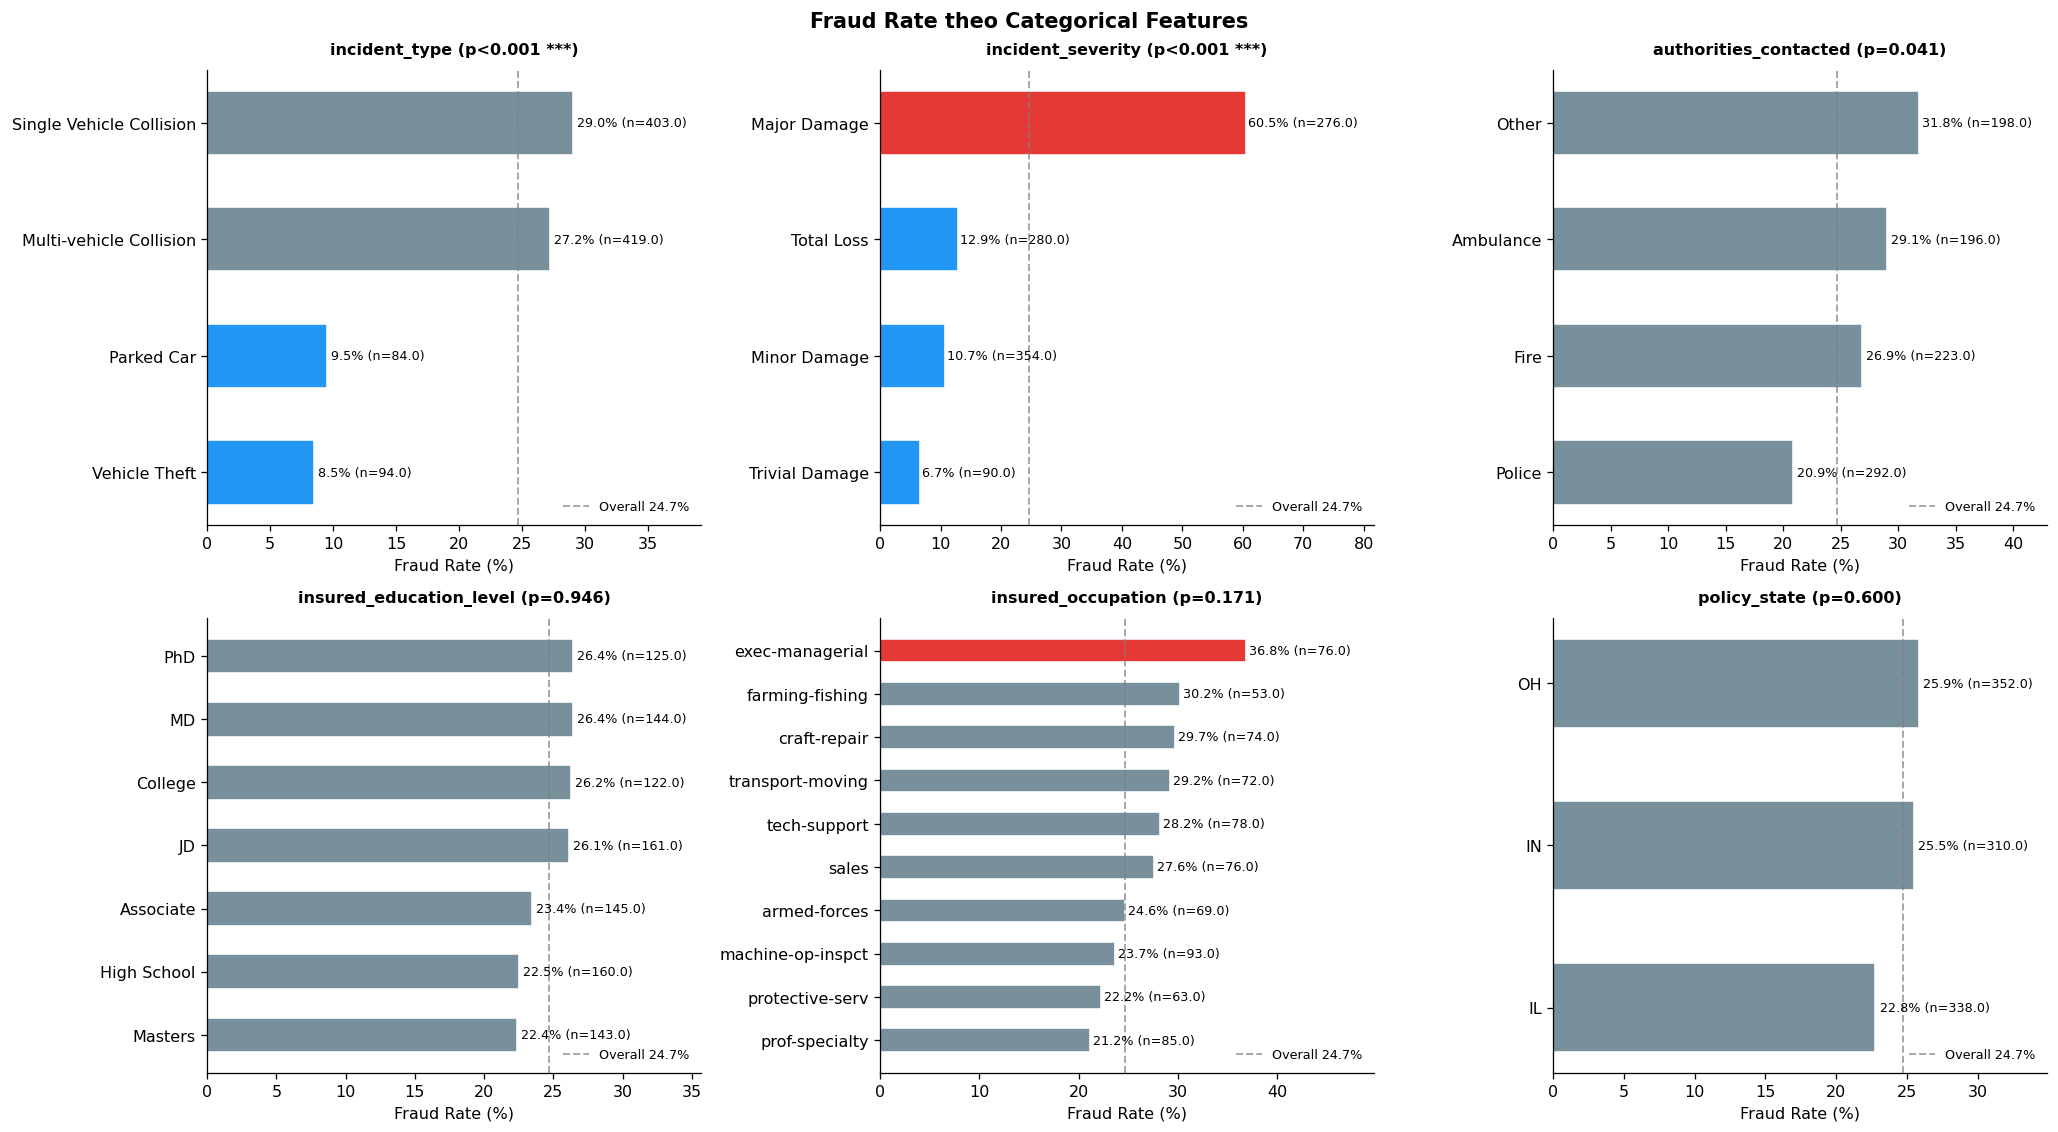

In [39]:
# ── Visualize top 6 categorical features ─────────────────────────────────────
PLOT_CATS = CAT_IMPORTANT[:6]
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()
overall_rate = df_raw["target"].mean() * 100

for i, col in enumerate(PLOT_CATS):
    grp = cat_stats[col].sort_values("fraud_rate_pct", ascending=True)
    bar_colors = [
        PALETTE["fraud"] if r > overall_rate * 1.3 else
        PALETTE["legit"] if r < overall_rate * 0.7 else
        PALETTE["neutral"]
        for r in grp["fraud_rate_pct"]
    ]
    bars = axes[i].barh(
        grp.index.astype(str),
        grp["fraud_rate_pct"],
        color=bar_colors, height=0.55, edgecolor="white",
    )
    for bar, (_, row) in zip(bars, grp.iterrows()):
        axes[i].text(
            bar.get_width() + 0.3,
            bar.get_y() + bar.get_height()/2,
            f"{row['fraud_rate_pct']:.1f}% (n={row['n']:,})",
            va="center", fontsize=8,
        )
    axes[i].axvline(overall_rate, color="gray", linestyle="--",
                    lw=1.2, alpha=0.7, label=f"Overall {overall_rate:.1f}%")
    axes[i].set_xlabel("Fraud Rate (%)")
    p_val = cat_stats[col].attrs["p_value"]
    sig_str = "p<0.001 ***" if p_val < 0.001 else f"p={p_val:.3f}"
    axes[i].set_title(f"{col} ({sig_str})", fontsize=10)
    axes[i].legend(fontsize=8, frameon=False)
    axes[i].set_xlim(0, grp["fraud_rate_pct"].max() * 1.35)

plt.suptitle("Fraud Rate theo Categorical Features",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fraud_02_categorical_eda.png", bbox_inches="tight")
plt.show()


## Fraud Rate theo Categorical Features

### Cách đọc biểu đồ
- **Cột xám** → fraud rate trên mức trung bình (24.7%)
- **Cột xanh** → fraud rate dưới mức trung bình
- **Cột đỏ** → nhóm có fraud rate cao bất thường
- **Đường đứt** → Overall fraud rate = 24.7%

---

### ✅ Biến có ý nghĩa thống kê

#### `incident_type` (p < 0.001 ***)
| Nhóm | Fraud Rate | |
|---|---|---|
| Single Vehicle Collision | 29.0% | ↑ Trên trung bình |
| Multi-vehicle Collision | 27.2% | ↑ Trên trung bình |
| Parked Car | 9.5% | ↓ Thấp |
| Vehicle Theft | 8.5% | ↓ Thấp |

Tai nạn một xe và đa xe có fraud rate cao hơn hẳn — dễ dàng khai
khống thiệt hại hơn so với xe đỗ hay trộm cắp.

---

#### `incident_severity` (p < 0.001 ***)
| Nhóm | Fraud Rate | |
|---|---|---|
| **Major Damage** | **60.5%** | 🔴 Rất cao |
| Total Loss | 12.9% | ↓ Thấp |
| Minor Damage | 10.7% | ↓ Thấp |
| Trivial Damage | 6.7% | ↓ Thấp |

Nghịch lý đáng chú ý: Major Damage có fraud rate **gấp ~5 lần** Total Loss.
Thiệt hại lớn nhưng không mất xe hoàn toàn → dễ thổi phồng mức độ thiệt hại.

---

#### `authorities_contacted` (p = 0.041 *)
| Nhóm | Fraud Rate |
|---|---|
| Other | 31.8% |
| Ambulance | 29.1% |
| Fire | 26.9% |
| Police | 20.9% |

Các vụ có **Police** tham gia có fraud rate thấp nhất — khó gian lận hơn
khi có hồ sơ cảnh sát chính thức.

---

### ❌ Biến không có ý nghĩa thống kê

#### `insured_education_level` (p = 0.946)
Fraud rate dao động rất nhỏ từ 22.4% đến 26.4% — **gần như bằng nhau**
ở mọi trình độ học vấn → biến này không có predictive power.

#### `insured_occupation` (p = 0.171)
`exec-managerial` có fraud rate 36.8% (đỏ) nhưng p-value = 0.171 →
**không đủ ý nghĩa thống kê**, có thể do sample size nhỏ (n=76).

#### `policy_state` (p = 0.600)
Ba bang OH, IN, IL có fraud rate gần bằng nhau (~23–26%) →
địa lý không phải yếu tố phân biệt trong dataset này.

---

### Kết luận

| Biến | Giữ lại | Lý do |
|---|---|---|
| `incident_severity` | ✅ | Tín hiệu mạnh nhất, p < 0.001 |
| `incident_type` | ✅ | Phân tách rõ, p < 0.001 |
| `authorities_contacted` | ✅ | Có ý nghĩa, p = 0.041 |
| `insured_education_level` | ❌ | p = 0.946, gần như random |
| `policy_state` | ❌ | p = 0.600, không phân tách |
| `insured_occupation` | ⚠️ | p = 0.171, cân nhắc tùy model |

## 6. EDA Biến Numerical — Distribution & Point-Biserial Correlation

**Point-biserial correlation** đo mức độ tương quan giữa biến số và biến nhị phân (fraud/legit).
Tương đương Pearson correlation nhưng áp dụng cho biến binary.

Point-Biserial Correlation với target (fraud):
                   Variable  correlation  p_value
              vehicle_claim       0.1700   0.0000
         total_claim_amount       0.1637   0.0000
             property_claim       0.1378   0.0000
               injury_claim       0.0910   0.0040
             umbrella_limit       0.0586   0.0639
number_of_vehicles_involved       0.0518   0.1014
                  witnesses       0.0495   0.1178
            bodily_injuries       0.0339   0.2845
              policy_number      -0.0294   0.3523
         months_as_customer       0.0205   0.5164
                insured_zip       0.0194   0.5407
              capital-gains      -0.0192   0.5448
               capital-loss      -0.0149   0.6387
          policy_deductable       0.0148   0.6398
      policy_annual_premium      -0.0145   0.6474
                        age       0.0121   0.7013
                  auto_year       0.0079   0.8023
   incident_hour_of_the_day       0.0043   0.8916


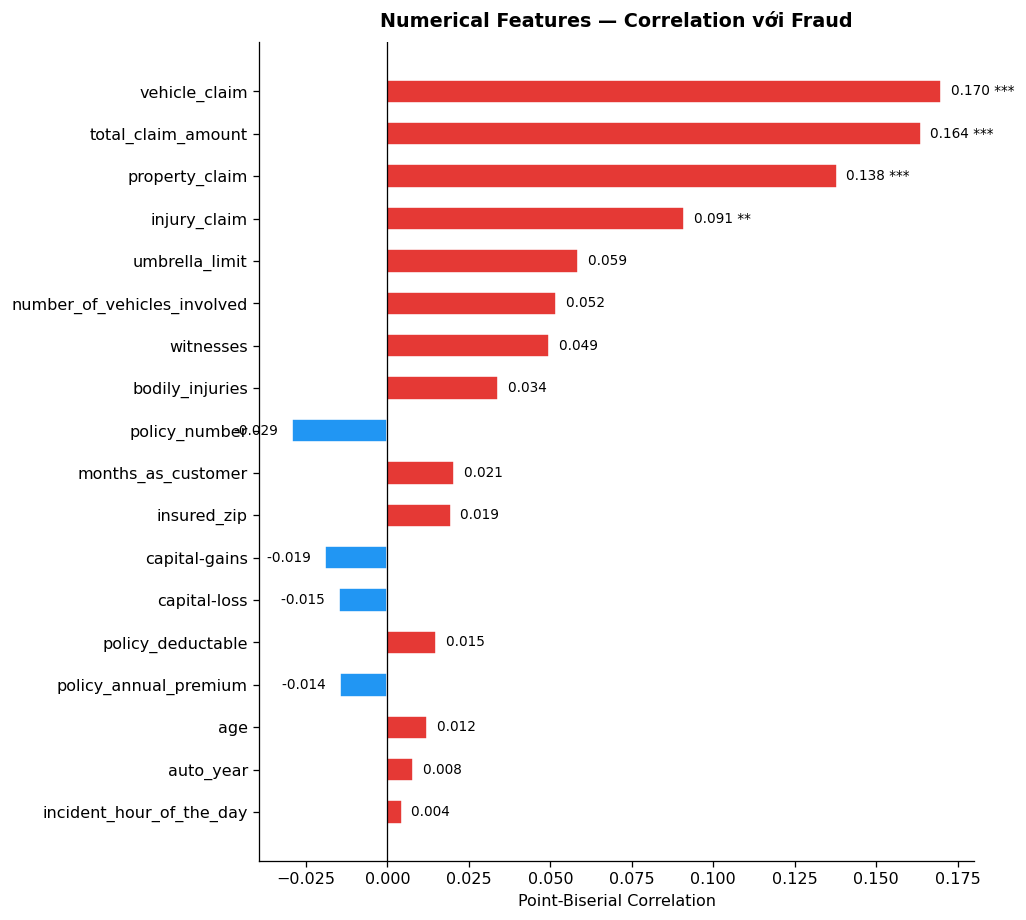

In [43]:
# ── Point-biserial correlation ───────────────────────────────────────────────
pb_corr = {}
for col in NUM_COLS:
    clean = df_raw[[col, "target"]].dropna()
    if clean[col].std() > 0:
        corr, p_val = pointbiserialr(clean["target"], clean[col])
        pb_corr[col] = {"correlation": corr, "p_value": p_val,
                        "abs_corr": abs(corr)}

pb_df = (pd.DataFrame(pb_corr).T
           .sort_values("abs_corr", ascending=False)
           .reset_index()
           .rename(columns={"index":"Variable"}))

print("Point-Biserial Correlation với target (fraud):")
print(pb_df[["Variable","correlation","p_value"]].to_string(index=False))

# Visualize
fig, ax = plt.subplots(figsize=(9, max(4, len(pb_df)*0.45)))
colors_corr = [
    PALETTE["fraud"] if c > 0 else PALETTE["legit"]
    for c in pb_df["correlation"]
]
bars = ax.barh(
    pb_df["Variable"][::-1],
    pb_df["correlation"][::-1],
    color=colors_corr[::-1],
    height=0.55, edgecolor="white",
)
for bar, (_, row) in zip(bars, pb_df[::-1].iterrows()):
    sig = "***" if row["p_value"]<0.001 else "**" if row["p_value"]<0.01 else "*" if row["p_value"]<0.05 else ""
    xpos = bar.get_width() + 0.003 if bar.get_width() >= 0 else bar.get_width() - 0.003
    ha   = "left" if bar.get_width() >= 0 else "right"
    ax.text(xpos, bar.get_y() + bar.get_height()/2,
            f"{row['correlation']:.3f} {sig}",
            va="center", ha=ha, fontsize=8.5)
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Point-Biserial Correlation")
ax.set_title("Numerical Features — Correlation với Fraud")
plt.tight_layout()
plt.savefig("fraud_03_numerical_correlation.png", bbox_inches="tight")
plt.show()


## Numerical Features — Correlation với Fraud

### Point-Biserial Correlation là gì?
Đo mức độ tương quan giữa biến **số** (numerical) và biến **nhị phân** (fraud/legit).
Tương tự Pearson correlation nhưng dùng khi một biến là categorical 0/1.

| Giá trị | Ý nghĩa |
|---|---|
| > 0 | Giá trị càng cao → càng có xu hướng Fraud |
| < 0 | Giá trị càng cao → càng có xu hướng Legit |
| Gần 0 | Gần như không liên quan |

---

### Phân tích từng biến

#### ✅ Biến có ý nghĩa thống kê (p < 0.05)

| Biến | Correlation | p-value | Nhận xét |
|---|---|---|---|
| `vehicle_claim` | 0.170 | 0.0000 | Giá trị bồi thường xe càng cao → fraud risk cao |
| `total_claim_amount` | 0.164 | 0.0000 | Tổng tiền claim càng lớn → fraud risk cao |
| `property_claim` | 0.138 | 0.0000 | Bồi thường tài sản cao → fraud risk cao |
| `injury_claim` | 0.091 | 0.0040 | Bồi thường thương tích cao → fraud risk cao |

Ba biến đầu tương quan chặt với nhau → cần kiểm tra **multicollinearity**.

---

#### ⚠️ Biến tương quan yếu, không có ý nghĩa thống kê

| Biến | Correlation | p-value |
|---|---|---|
| `umbrella_limit` | 0.059 | 0.0639 |
| `number_of_vehicles_involved` | 0.052 | 0.1014 |
| `witnesses` | 0.049 | 0.1178 |
| `bodily_injuries` | 0.034 | 0.2845 |

---

#### ❌ Biến gần như không liên quan

| Biến | Correlation | Nhận xét |
|---|---|---|
| `policy_number` | -0.029 | ID — không có ý nghĩa, nên loại bỏ |
| `capital-gains` | -0.019 | Không liên quan |
| `capital-loss` | -0.015 | Không liên quan |
| `age` | 0.012 | Không phân tách được fraud |
| `auto_year` | 0.008 | Không liên quan |
| `incident_hour_of_the_day` | 0.004 | Không liên quan |

---

### Kết luận

| Nhóm | Biến | Hành động |
|---|---|---|
| **Giữ lại** | `vehicle_claim`, `total_claim_amount`, `property_claim`, `injury_claim` | Correlation cao, p < 0.05 |
| **Cân nhắc** | `umbrella_limit`, `witnesses`, `number_of_vehicles_involved` | Tương quan yếu nhưng có thể có ích trong ensemble model |
| **Loại bỏ** | `policy_number`, `age`, `auto_year`, `incident_hour_of_the_day` | Gần như không có predictive power |

> **Lưu ý:** `vehicle_claim`, `total_claim_amount`, `property_claim` nhiều khả năng
> **tương quan cao với nhau** vì cùng đo giá trị tiền bồi thường → kiểm tra VIF
> trước khi đưa cả 3 vào model.

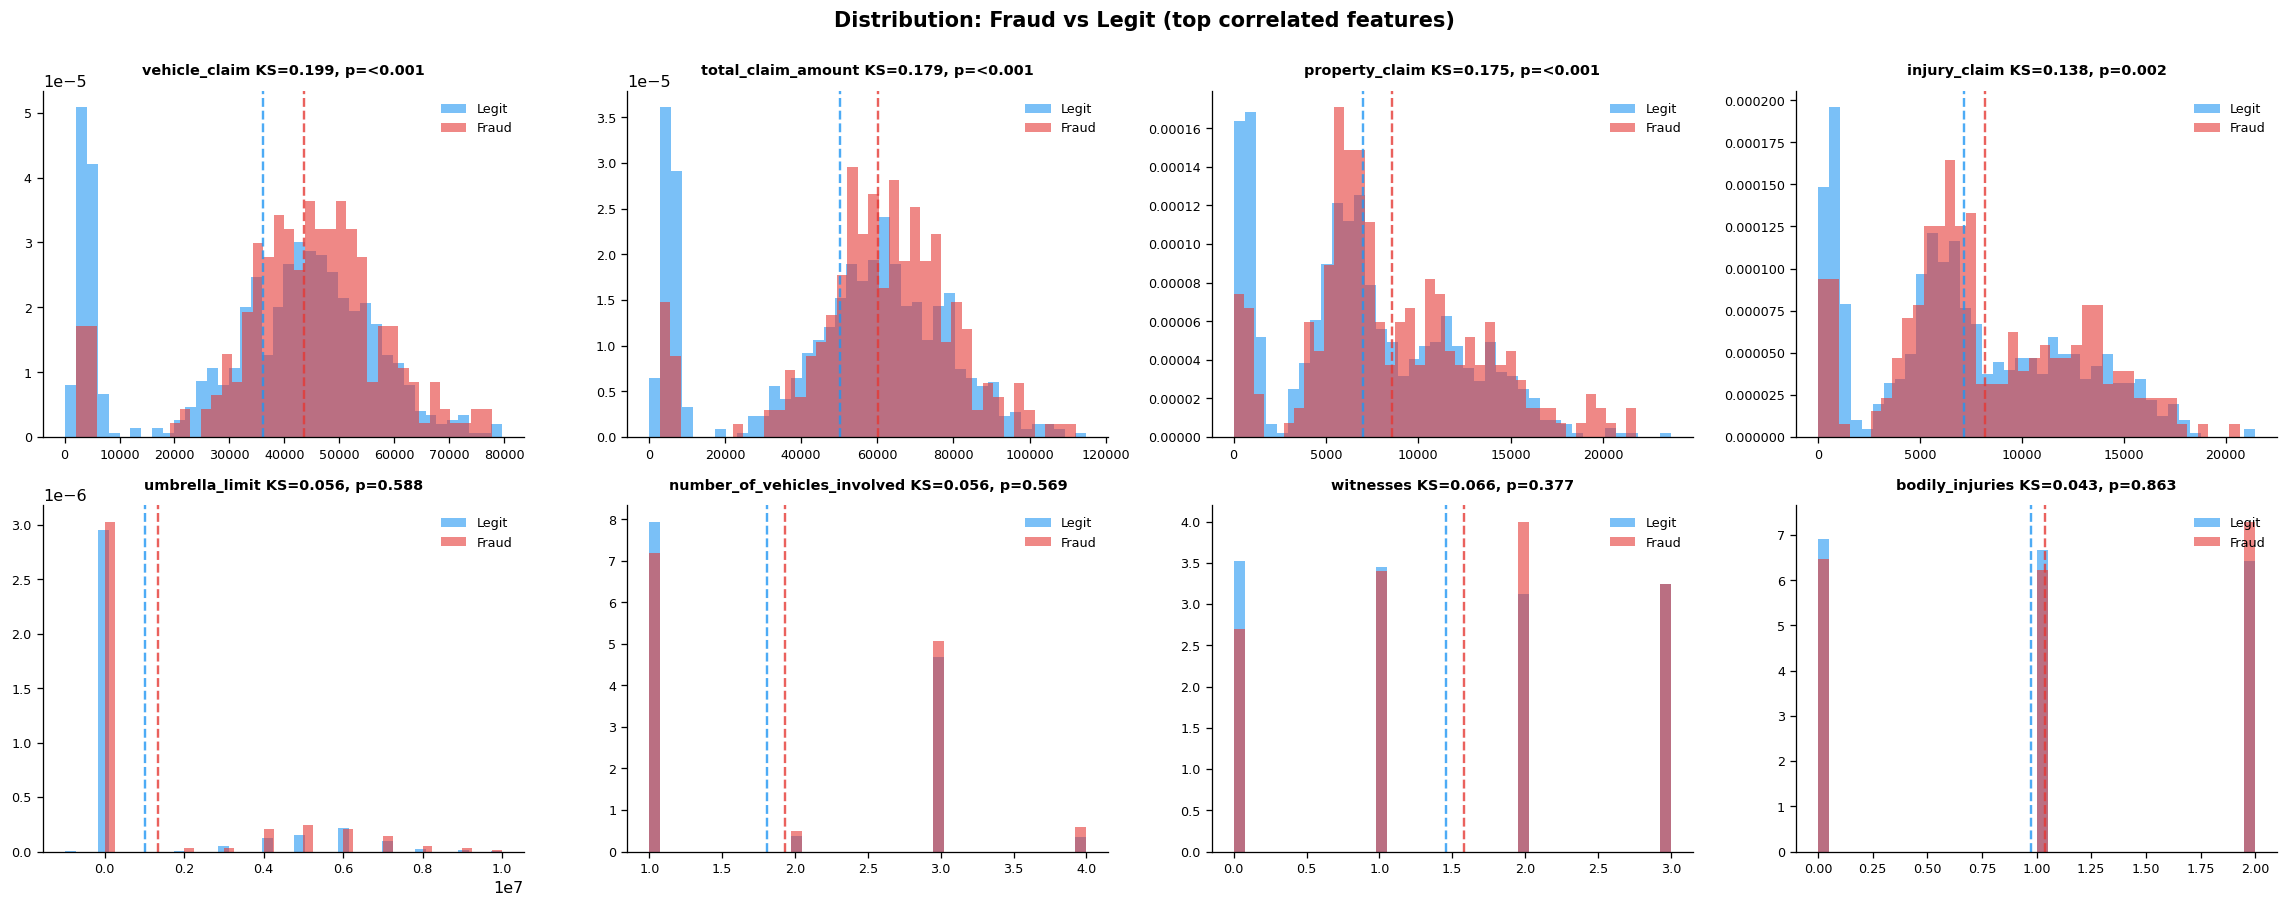

In [56]:
# ── Distribution plots: Fraud vs Legit ───────────────────────────────────────
# Chỉ plot top 8 biến có correlation cao nhất
top_num = pb_df.head(min(8, len(pb_df)))["Variable"].tolist()

fig, axes = plt.subplots(2, 4, figsize=(20, 8))
axes = axes.flatten()

for i, col in enumerate(top_num):
    legit_vals = df_raw.loc[df_raw["target"]==0, col].dropna()
    fraud_vals = df_raw.loc[df_raw["target"]==1, col].dropna()

    axes[i].hist(legit_vals, bins=40, alpha=0.6, color=PALETTE["legit"],
                 label="Legit", density=True, edgecolor="none")
    axes[i].hist(fraud_vals, bins=40, alpha=0.6, color=PALETTE["fraud"],
                 label="Fraud", density=True, edgecolor="none")

    axes[i].axvline(legit_vals.mean(), color=PALETTE["legit"],
                    linestyle="--", lw=1.5, alpha=0.8)
    axes[i].axvline(fraud_vals.mean(), color=PALETTE["fraud"],
                    linestyle="--", lw=1.5, alpha=0.8)

    # KS test
    ks_stat, ks_p = stats.ks_2samp(legit_vals, fraud_vals)
    axes[i].set_title(
        f"{col} KS={ks_stat:.3f}, p={'<0.001' if ks_p<0.001 else f'{ks_p:.3f}'}",
        fontsize=9,
    )
    axes[i].legend(fontsize=8, frameon=False)
    axes[i].tick_params(labelsize=8)

for j in range(i+1, len(axes)):
    axes[j].set_visible(False)

plt.suptitle("Distribution: Fraud vs Legit (top correlated features)",
             fontsize=13, fontweight="bold")
plt.tight_layout()
plt.savefig("fraud_04_num_distributions.png", bbox_inches="tight")
plt.show()


## 7. Phân tích Temporal Patterns — Dấu hiệu thời gian của Fraud

Fraud thường có **patterns theo thời gian** đặc trưng:
- Claim được nộp ngay sau khi mua policy (policy age rất ngắn)
- Incident xảy ra vào cuối tuần hoặc đêm (ít nhân chứng hơn)
- Claim delay bất thường (nộp quá muộn hoặc quá nhanh)

Date columns found: ['policy_bind_date', 'incident_date']
  Parsed: policy_bind_date → datetime64[ns]
  Parsed: incident_date → datetime64[ns]

policy_age_days created:
          count       mean        std      min        25%        50%  \
target                                                                 
0      753.0000 4,737.7000 2,692.1000 -20.0000 2,450.0000 4,734.0000   
1      247.0000 4,743.5000 2,674.6000  82.0000 2,525.0000 4,638.0000   

              75%        max  
target                        
0      7,067.0000 9,172.0000  
1      7,103.0000 9,124.0000  


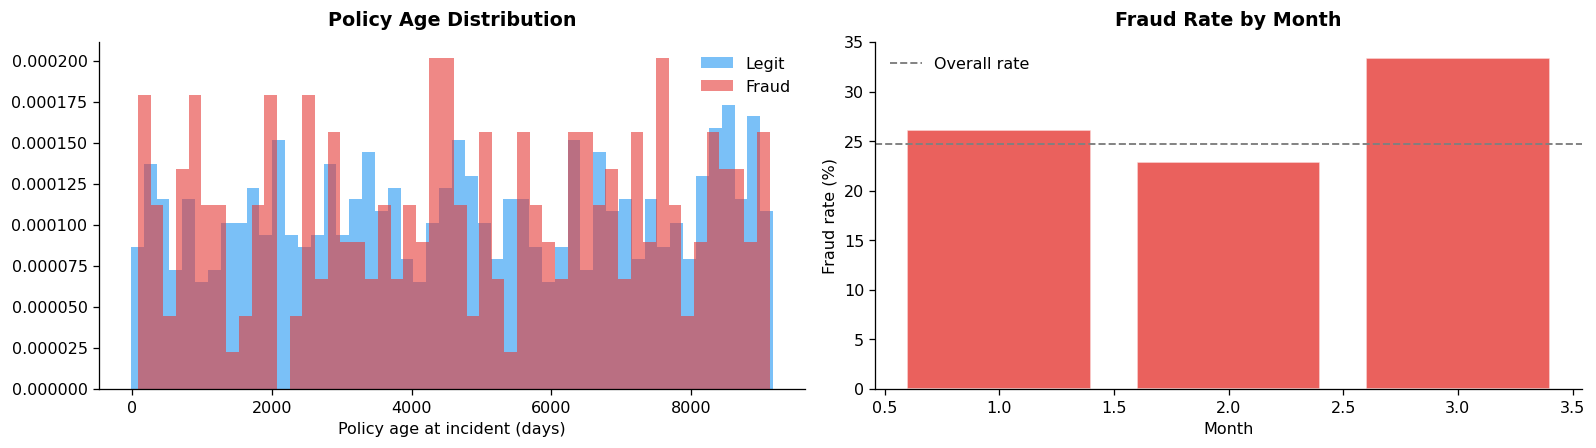

In [46]:
df = df_raw.copy()

# ── Parse dates nếu có ───────────────────────────────────────────────────────
date_cols = [c for c in df.columns if "date" in c.lower()]
print(f"Date columns found: {date_cols}")

for col in date_cols:
    try:
        df[col] = pd.to_datetime(df[col], errors="coerce")
        print(f"  Parsed: {col} → {df[col].dtype}")
    except Exception as e:
        print(f"  Could not parse {col}: {e}")

# ── Policy age (months) at time of incident ───────────────────────────────────
if "policy_bind_date" in df.columns and "incident_date" in df.columns:
    df["policy_age_days"] = (
        df["incident_date"] - df["policy_bind_date"]
    ).dt.days
    print(f"\npolicy_age_days created:")
    print(df.groupby("target")["policy_age_days"].describe().round(1))

    # Visualize
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    for t, lbl, col_ in [(0,"Legit",PALETTE["legit"]),(1,"Fraud",PALETTE["fraud"])]:
        vals = df.loc[df["target"]==t, "policy_age_days"].dropna()
        axes[0].hist(vals, bins=50, alpha=0.6, color=col_,
                     label=lbl, density=True, edgecolor="none")
    axes[0].set_xlabel("Policy age at incident (days)")
    axes[0].set_title("Policy Age Distribution")
    axes[0].legend(frameon=False)

    # Incident by month
    if not df["incident_date"].isna().all():
        df["incident_month"] = df["incident_date"].dt.month
        monthly = df.groupby(["incident_month","target"])["target"].count().unstack()
        if 0 in monthly.columns and 1 in monthly.columns:
            monthly["fraud_rate"] = monthly[1] / (monthly[0] + monthly[1]) * 100
            axes[1].bar(monthly.index, monthly["fraud_rate"],
                        color=PALETTE["fraud"], alpha=0.8, edgecolor="white")
            axes[1].axhline(df["target"].mean()*100, color="gray",
                            linestyle="--", lw=1.2, label="Overall rate")
            axes[1].set_xlabel("Month")
            axes[1].set_ylabel("Fraud rate (%)")
            axes[1].set_title("Fraud Rate by Month")
            axes[1].legend(frameon=False)

    plt.tight_layout()
    plt.savefig("fraud_05_temporal.png", bbox_inches="tight")
    plt.show()
else:
    print("Không tìm thấy date columns — bỏ qua temporal analysis")
    print("→ Sẽ tạo synthetic time features ở Bước 2 (Feature Engineering)")

## Date Features Analysis

### Xử lý cột ngày tháng
Hai cột date được parse sang datetime và tạo ra biến mới:

```
policy_bind_date  ──┐
                    ├──► policy_age_days = incident_date - policy_bind_date
incident_date     ──┘
```

---

### Policy Age Distribution — Thống kê theo Target

| | Legit (0) | Fraud (1) |
|---|---|---|
| Count | 753 | 247 |
| Mean | 4,737.7 ngày (~13 năm) | 4,743.5 ngày (~13 năm) |
| Min | -20 ngày ⚠️ | 82 ngày |
| 25% | 2,450 ngày | 2,525 ngày |
| 50% | 4,734 ngày | 4,638 ngày |
| 75% | 7,067 ngày | 7,103 ngày |
| Max | 9,172 ngày | 9,124 ngày |

**Nhận xét:**
- Mean policy age giữa Legit và Fraud **gần như bằng nhau** (~13 năm)
  → `policy_age_days` một mình khó phân tách fraud
- **Min = -20 ngày** ở nhóm Legit → dữ liệu bất thường, incident xảy ra
  **trước** khi ký hợp đồng bảo hiểm, cần kiểm tra lại

---

### Policy Age Distribution Chart

Phân phối Legit (xanh) và Fraud (đỏ) **chồng lên nhau** ở mọi khoảng
policy age → xác nhận biến này **không phân tách tốt** một mình.

---

### Fraud Rate by Month

| Month | Fraud Rate | So với Overall (24.7%) |
|---|---|---|
| 1 | ~22% | ↓ Dưới trung bình |
| 2 | ~23% | ↓ Dưới trung bình |
| **3** | **~33%** | ↑ **Cao hơn đáng kể** |

Tháng 3 có fraud rate **~33%** — cao hơn 8 điểm % so với overall.

> **Lưu ý:** Chỉ có 3 tháng dữ liệu → sample size nhỏ, cần thận trọng
> khi kết luận về tính thời vụ. Cần thêm dữ liệu để xác nhận pattern này.

---
## Date Features Analysis

### Xử lý cột ngày tháng
Hai cột date được parse sang datetime và tạo ra biến mới:

```
policy_bind_date  ──┐
                    ├──► policy_age_days = incident_date - policy_bind_date
incident_date     ──┘
```

---

### Policy Age Distribution — Thống kê theo Target

| | Legit (0) | Fraud (1) |
|---|---|---|
| Count | 753 | 247 |
| Mean | 4,737.7 ngày (~13 năm) | 4,743.5 ngày (~13 năm) |
| Min | -20 ngày ⚠️ | 82 ngày |
| 25% | 2,450 ngày | 2,525 ngày |
| 50% | 4,734 ngày | 4,638 ngày |
| 75% | 7,067 ngày | 7,103 ngày |
| Max | 9,172 ngày | 9,124 ngày |

**Nhận xét:**
- Mean policy age giữa Legit và Fraud **gần như bằng nhau** (~13 năm)
  → `policy_age_days` một mình khó phân tách fraud
- **Min = -20 ngày** ở nhóm Legit → dữ liệu bất thường, incident xảy ra
  **trước** khi ký hợp đồng bảo hiểm, cần kiểm tra lại

---

### Policy Age Distribution Chart

Phân phối Legit (xanh) và Fraud (đỏ) **chồng lên nhau** ở mọi khoảng
policy age → xác nhận biến này **không phân tách tốt** một mình.

---

### Fraud Rate by Month

| Month | Fraud Rate | So với Overall (24.7%) |
|---|---|---|
| 1 | ~22% | ↓ Dưới trung bình |
| 2 | ~23% | ↓ Dưới trung bình |
| **3** | **~33%** | ↑ **Cao hơn đáng kể** |

Tháng 3 có fraud rate **~33%** — cao hơn 8 điểm % so với overall.

> **Lưu ý:** Chỉ có 3 tháng dữ liệu → sample size nhỏ, cần thận trọng
> khi kết luận về tính thời vụ. Cần thêm dữ liệu để xác nhận pattern này.

---

### Kết luận

| Biến | Hành động | Lý do |
|---|---|---|
| `policy_age_days` | ⚠️ Cân nhắc | Phân phối Legit/Fraud gần giống nhau |
| `month` (từ incident_date) | ✅ Giữ lại | Tháng 3 có tín hiệu fraud cao |
| Giá trị âm (min = -20) | 🔍 Kiểm tra | Data quality issue cần xử lý |
### Kết luận

| Biến | Hành động | Lý do |
|---|---|---|
| `policy_age_days` | ⚠️ Cân nhắc | Phân phối Legit/Fraud gần giống nhau |
| `month` (từ incident_date) | ✅ Giữ lại | Tháng 3 có tín hiệu fraud cao |
| Giá trị âm (min = -20) | 🔍 Kiểm tra | Data quality issue cần xử lý |

## 8. Phân tích Missing Values

In [60]:
def missing_summary(df):
    total   = df.isnull().sum()
    pct     = total / len(df) * 100
    dtype   = df.dtypes
    summary = pd.DataFrame({
        "Missing count": total,
        "Missing %":     pct.round(2),
        "Dtype":         dtype,
    }).sort_values("Missing %", ascending=False)
    return summary[summary["Missing count"] > 0]

miss = missing_summary(df_raw)
if len(miss) == 0:
    print("✓ Không có missing values trong dataset")
else:
    print(f"Số cột có missing: {len(miss)}")
    print(miss.to_string())

# ── Kiểm tra ký tự "?" thường dùng thay cho NaN trong insurance data ─────────
question_mark_cols = []
for col in CAT_COLS:
    if "?" in df_raw[col].astype(str).values:
        n_q = (df_raw[col].astype(str) == "?").sum()
        question_mark_cols.append((col, n_q))
        print(f"  [{col}] có {n_q} giá trị '?' — cần replace với NaN")

if not question_mark_cols:
    print("✓ Không có ký tự '?' trong categorical columns")

Số cột có missing: 2
                       Missing count  Missing %    Dtype
_c39                            1000   100.0000  float64
authorities_contacted             91     9.1000   object
  [collision_type] có 178 giá trị '?' — cần replace với NaN
  [property_damage] có 360 giá trị '?' — cần replace với NaN
  [police_report_available] có 343 giá trị '?' — cần replace với NaN


## 9. Xử lý Missing Values & Làm sạch sơ bộ

In [67]:
df = df_raw.copy()

# ── 1. Replace '?' với NaN ────────────────────────────────────────────────────
for col in CAT_COLS:
    df[col] = df[col].replace("?", np.nan)

n_nan_after = df.isnull().sum().sum()
print(f"NaN sau khi replace '?': {n_nan_after}")

# ── 2. Drop cột không có giá trị dự báo ──────────────────────────────────────
# policy_number: ID duy nhất — không có predictive value
# _c39 hoặc cột unnamed nếu có
DROP_COLS = []
for col in df.columns:
    if col.lower() in ["policy_number", "unnamed: 0", "_c39"]:
        DROP_COLS.append(col)
    elif df[col].nunique() == len(df):   # Tất cả unique → likely ID column
        DROP_COLS.append(col)

if DROP_COLS:
    df = df.drop(columns=DROP_COLS)
    print(f"Dropped ID/useless columns: {DROP_COLS}")

# ── 3. Xử lý '?' còn lại trong categorical ───────────────────────────────────
for col in [c for c in df.columns if df[c].dtype == "object" and c != "target"]:
    n_null = df[col].isnull().sum()
    if n_null > 0:
        mode_val = df[col].mode()[0]
        df[col] = df[col].fillna(mode_val)
        print(f"  {col}: filled {n_null} NaN với mode='{mode_val}'")

# ── 4. Xử lý numerical missing ───────────────────────────────────────────────
# Sync lại NUM_COLS sau khi drop columns
NUM_COLS = [c for c in NUM_COLS if c in df.columns]
print(f"NUM_COLS sau sync: {NUM_COLS}")
for col in NUM_COLS:
    n_null = df[col].isnull().sum()
    if n_null > 0:
        med = df[col].median()
        df[col] = df[col].fillna(med)
        print(f"  {col}: filled {n_null} NaN với median={med:.2f}")

print(f"\n✓ Missing values sau xử lý: {df.isnull().sum().sum()}")
print(f"✓ Shape: {df.shape}")


NaN sau khi replace '?': 1972
Dropped ID/useless columns: ['policy_number', 'incident_location', '_c39']
  collision_type: filled 178 NaN với mode='Rear Collision'
  authorities_contacted: filled 91 NaN với mode='Police'
  property_damage: filled 360 NaN với mode='NO'
  police_report_available: filled 343 NaN với mode='NO'
NUM_COLS sau sync: ['months_as_customer', 'age', 'policy_deductable', 'policy_annual_premium', 'umbrella_limit', 'insured_zip', 'capital-gains', 'capital-loss', 'incident_hour_of_the_day', 'number_of_vehicles_involved', 'bodily_injuries', 'witnesses', 'total_claim_amount', 'injury_claim', 'property_claim', 'vehicle_claim', 'auto_year']

✓ Missing values sau xử lý: 0
✓ Shape: (1000, 37)


## 10. Outlier Check cho Numerical Features

**Lưu ý quan trọng:** Trong fraud detection, một số outlier có thể là **dấu hiệu fraud** thực sự
(ví dụ: claim amount cực cao, số lần claim nhiều bất thường).
→ Không winsorize tất cả — cần phân tích trước khi quyết định.

In [70]:
def outlier_report(df, cols):
    rows = []
    for col in cols:
        s = df[col].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        iqr    = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        n_out  = ((s < lo) | (s > hi)).sum()

        # Fraud rate trong outlier group
        out_mask    = (df[col] < lo) | (df[col] > hi)
        fraud_in_out = df.loc[out_mask, "target"].mean() * 100 if out_mask.sum() > 0 else 0
        fraud_in_norm= df.loc[~out_mask, "target"].mean() * 100

        rows.append({
            "Column":              col,
            "N outliers":          n_out,
            "Outlier %":           round(n_out/len(s)*100, 2),
            "Fraud % in outliers": round(fraud_in_out, 1),
            "Fraud % normal":      round(fraud_in_norm, 1),
            "Delta":               round(fraud_in_out - fraud_in_norm, 1),
        })
    return (pd.DataFrame(rows)
              .sort_values("Delta", ascending=False)
              .reset_index(drop=True))

num_present = [c for c in NUM_COLS if c in df.columns]
out_df = outlier_report(df, num_present)
print("Outlier analysis — Fraud rate trong outlier group vs normal:")
print(out_df.to_string(index=False))

print()
print("Columns với outlier fraud rate cao hơn normal (keep as features!):")
keep_outlier = out_df[out_df["Delta"] > 5]
for _, row in keep_outlier.iterrows():
    print(f"  {row['Column']:30s} Delta = +{row['Delta']:.1f}%  → Có giá trị dự báo")


Outlier analysis — Fraud rate trong outlier group vs normal:
                     Column  N outliers  Outlier %  Fraud % in outliers  Fraud % normal    Delta
      policy_annual_premium           9     0.9000              33.3000         24.6000   8.7000
             property_claim           6     0.6000              33.3000         24.6000   8.7000
             umbrella_limit         202    20.2000              29.7000         23.4000   6.3000
                        age           4     0.4000              25.0000         24.7000   0.3000
         months_as_customer           0     0.0000               0.0000         24.7000 -24.7000
            bodily_injuries           0     0.0000               0.0000         24.7000 -24.7000
              vehicle_claim           0     0.0000               0.0000         24.7000 -24.7000
               injury_claim           0     0.0000               0.0000         24.7000 -24.7000
         total_claim_amount           1     0.1000               0

## 11. Lưu dữ liệu sạch & EDA Summary

In [73]:
# ── Final check ──────────────────────────────────────────────────────────────
print("═══ KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU XỬ LÝ ═══")
print(f"  Shape          : {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"  Missing values : {df.isnull().sum().sum()}")
print(f"  Fraud cases    : {df['target'].sum():,} ({df['target'].mean()*100:.1f}%)")
print(f"  Legit cases    : {(df['target']==0).sum():,}")
print(f"  Imbalance ratio: {(df['target']==0).sum()/df['target'].sum():.1f}:1")

# ── Save cleaned data ─────────────────────────────────────────────────────────
df.to_csv("fraud_cleaned.csv", index=False)
print("\n✓ Saved: fraud_cleaned.csv")

# ── Save EDA summary JSON ─────────────────────────────────────────────────────
eda_summary = {
    "n_records":        int(df.shape[0]),
    "n_features":       int(df.shape[1] - 1),
    "fraud_count":      int(df["target"].sum()),
    "legit_count":      int((df["target"]==0).sum()),
    "fraud_rate":       round(float(df["target"].mean()), 4),
    "imbalance_ratio":  round(float((df["target"]==0).sum() / df["target"].sum()), 2),
    "n_categorical":    int(df.select_dtypes("object").shape[1]),
    "n_numerical":      int(df.select_dtypes(["int64","float64"]).shape[1] - 1),
    "top_cat_features": [
        {"column": col, "p_value": round(cat_stats[col].attrs["p_value"], 6)}
        for col in list(cat_stats.keys())[:5]
        if col in cat_stats and cat_stats[col].attrs["p_value"] < 0.05
    ],
    "top_num_features": pb_df.head(5)[["Variable","correlation"]].to_dict("records"),
    "missing_after_clean": int(df.isnull().sum().sum()),
}
with open("eda_summary.json", "w") as f:
    json.dump(eda_summary, f, indent=2)
print("✓ Saved: eda_summary.json")

print()
print("═══ TÓM TẮT BƯỚC 1 ═══")
print(f"  Fraud rate        : {df['target'].mean()*100:.1f}%")
print(f"  Imbalance ratio   : {(df['target']==0).sum()/df['target'].sum():.1f}:1")
print(f"  Top categorical   : {list(cat_stats.keys())[:3]}")
print(f"  Top numerical     : {pb_df.head(3)['Variable'].tolist()}")
print()
print("─── Bước tiếp theo: Bước 2 — Feature Engineering ───")

═══ KIỂM TRA CHẤT LƯỢNG DỮ LIỆU SAU XỬ LÝ ═══
  Shape          : 1,000 rows × 37 columns
  Missing values : 0
  Fraud cases    : 247 (24.7%)
  Legit cases    : 753
  Imbalance ratio: 3.0:1

✓ Saved: fraud_cleaned.csv
✓ Saved: eda_summary.json

═══ TÓM TẮT BƯỚC 1 ═══
  Fraud rate        : 24.7%
  Imbalance ratio   : 3.0:1
  Top categorical   : ['incident_type', 'incident_severity', 'authorities_contacted']
  Top numerical     : ['vehicle_claim', 'total_claim_amount', 'property_claim']

─── Bước tiếp theo: Bước 2 — Feature Engineering ───
